# FINAL FEVER Evidence-Based Classifier Training

This is the **final full-data training notebook**, adapted from the tested trial notebook.

It deliberately preserves the working choices from the trial:
- `microsoft/deberta-v3-base`
- LoRA target modules: `query_proj`, `value_proj`
- `modules_to_save=["classifier"]`
- `dtype=torch.float32` when supported by the installed Transformers version
- Runtime-compatible `TrainingArguments` and `Trainer` constructor arguments
- Gold evidence for SUPPORTS/REFUTES and sampled-corpus evidence for NEI
- Validation Macro-F1 checkpoint selection, error analysis, and saved predictions

**Difference from the trial:** this notebook uses every row in `train_classifier.jsonl` and `dev_classifier.jsonl`; it does not take 12,000/2,000 stratified subsets.

The official paper test file is not used during training or model selection. Its evaluation is an explicit final optional step at the end.

Update `DATA_DIR` only if your Kaggle dataset mount path differs.

## 1. Install dependencies

In [1]:
!pip uninstall -y -q torchao
!pip -q install -U transformers peft accelerate datasets scikit-learn pandas matplotlib seaborn sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires 

In [2]:
import transformers, peft, accelerate, datasets
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)
print("Datasets:", datasets.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Transformers: 5.22.2
PEFT: 0.21.2
Accelerate: 1.15.0
Datasets: 5.2.0


## 2. Imports, reproducibility, and configuration

In [3]:
import os, json, random, time, gc
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer,
    EarlyStoppingCallback, set_seed
)
from peft import LoraConfig, TaskType, get_peft_model

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Update these paths for your runtime.
# Colab example: /content/drive/MyDrive/FACTLENS/fever-data/processed
# Kaggle example: /kaggle/input/your-dataset/processed
DATA_DIR = Path("/kaggle/input/datasets/lk1920/fever-data")
OUTPUT_DIR = Path("/kaggle/working/fever_deberta_lora_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = DATA_DIR / "train_classifier.jsonl"
DEV_FILE = DATA_DIR / "dev_classifier.jsonl"

MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LENGTH = 256

NUM_EPOCHS = 4
LEARNING_RATE = 2e-4
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 1000
GRAD_ACCUM_STEPS = 1

# LoRA configuration
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.10
LORA_TARGET_MODULES = ["query_proj", "value_proj"]

LABEL2ID = {"SUPPORTS": 0, "REFUTES": 1, "NEI": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Train file exists:", TRAIN_FILE.exists(), TRAIN_FILE)
print("Dev file exists:", DEV_FILE.exists(), DEV_FILE)

Torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Train file exists: True /kaggle/input/datasets/lk1920/fever-data/train_classifier.jsonl
Dev file exists: True /kaggle/input/datasets/lk1920/fever-data/dev_classifier.jsonl


## 3. Load and validate the prepared FEVER data

In [4]:
def read_jsonl(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run fever_data_prep.ipynb first and make sure "
            "the processed JSONL files are in DATA_DIR."
        )
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if line.strip():
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError as e:
                    raise ValueError(f"Invalid JSON at {path}:{line_no}") from e
    return rows

train_raw = read_jsonl(TRAIN_FILE)
dev_raw = read_jsonl(DEV_FILE)

print("Raw train rows:", len(train_raw))
print("Raw dev rows:", len(dev_raw))
print("Train labels:", Counter(x.get("label") for x in train_raw))
print("Dev labels:", Counter(x.get("label") for x in dev_raw))

def validate_row(row):
    assert row.get("label") in LABEL2ID, f"Unexpected label: {row.get('label')}"
    assert isinstance(row.get("claim"), str) and row["claim"].strip(), "Missing claim"
    evidence = row.get("evidence")
    assert isinstance(evidence, list) and len(evidence) > 0, "Empty evidence"
    assert all(isinstance(e.get("text"), str) and e["text"].strip() for e in evidence), "Bad evidence text"
    if row["label"] in ("SUPPORTS", "REFUTES"):
        assert row.get("evidence_source") == "gold", "Positive label without gold evidence"
    if row["label"] == "NEI":
        assert row.get("evidence_source") == "sampled_corpus", "NEI row without sampled evidence"

for row in train_raw + dev_raw:
    validate_row(row)

print("Basic row validation passed.")

Raw train rows: 186217
Raw dev rows: 24242
Train labels: Counter({'SUPPORTS': 115573, 'REFUTES': 42913, 'NEI': 27731})
Dev labels: Counter({'SUPPORTS': 9508, 'REFUTES': 9449, 'NEI': 5285})
Basic row validation passed.


## 4. Inspect label/evidence examples before training

In [5]:
def show_examples(rows, n=2, seed=SEED):
    rng = random.Random(seed)
    for label in LABEL2ID:
        candidates = [r for r in rows if r["label"] == label]
        print("\\n" + "="*90 + "\\nLABEL:", label, "| available:", len(candidates))
        for row in rng.sample(candidates, min(n, len(candidates))):
            print("Claim:", row["claim"])
            print("Evidence source:", row.get("evidence_source"))
            for ev in row["evidence"][:4]:
                print(" -", ev["text"])
show_examples(train_raw, n=2)

\n==========================================================================================\nLABEL: SUPPORTS | available: 115573
Claim: Richard Dreyfuss has won an Academy Award.
Evidence source: gold
 - Dreyfuss won the Academy Award for Best Actor in 1977 for The Goodbye Girl , and was nominated in 1995 for Mr. Holland 's Opus .
Claim: Dragon Ball has been made into animated films.
Evidence source: gold
 - Several companies have developed various types of merchandising based on the series leading to a large media franchise that includes films , both animated and live-action , collectible trading card games , numerous action figures , along with several collections of soundtracks and a large number of video games .
\n==========================================================================================\nLABEL: REFUTES | available: 42913
Claim: Noam Chomsky refused to study linguistics.
Evidence source: gold
 - Avram Noam Chomsky -LRB- -LSB- æ ` vrɑːm _ ` noʊm_ˈtʃɒmski -RSB- ; bor

## 5. Build classifier inputs and sample subsets

We concatenate the claim and all sentences from one evidence group. This preserves the FEVER annotation unit: **one claim + one complete evidence group → one label**. We do not flatten individual evidence sentences into independent labels.

The subset is sampled separately within each official split and approximately preserves its label proportions.

In [6]:
def to_model_row(row):
    evidence_text = " ".join(
        ev["text"].strip()
        for ev in row["evidence"]
        if ev.get("text", "").strip()
    )
    text = (
        "Claim: " + row["claim"].strip() +
        "\\nEvidence: " + evidence_text
    )
    return {
        "id": str(row.get("id", "")),
        "text": text,
        "label": LABEL2ID[row["label"]],
        "label_name": row["label"],
        "evidence_source": row.get("evidence_source", "unknown"),
        "claim": row["claim"],
        "evidence_text": evidence_text,
    }

# FINAL TRAINING: use every row in the prepared official train/dev files.
train_rows = [to_model_row(r) for r in train_raw]
dev_rows = [to_model_row(r) for r in dev_raw]

print("Full training size:", len(train_rows))
print("Full validation size:", len(dev_rows))
print("Train distribution:", Counter(x["label_name"] for x in train_rows))
print("Dev distribution:", Counter(x["label_name"] for x in dev_rows))

# Check split overlap only for non-empty IDs.
train_ids = {x["id"] for x in train_rows if x["id"]}
dev_ids = {x["id"] for x in dev_rows if x["id"]}
overlap = train_ids & dev_ids
print("Overlapping claim IDs:", len(overlap))
assert not overlap, "Train/dev claim ID overlap detected!"

# Save the complete claim/evidence audit for manual review.
audit_rows = []
for split_name, rows in [("train", train_rows), ("dev", dev_rows)]:
    for row in rows:
        audit_rows.append({
            "split": split_name,
            "id": row["id"],
            "claim": row["claim"],
            "label": row["label_name"],
            "evidence_source": row["evidence_source"],
            "evidence": row["evidence_text"],
        })

audit_path = OUTPUT_DIR / "label_evidence_audit.csv"
pd.DataFrame(audit_rows).to_csv(audit_path, index=False)
print("Full label/evidence audit saved:", audit_path)


Full training size: 186217
Full validation size: 24242
Train distribution: Counter({'SUPPORTS': 115573, 'REFUTES': 42913, 'NEI': 27731})
Dev distribution: Counter({'SUPPORTS': 9508, 'REFUTES': 9449, 'NEI': 5285})
Overlapping claim IDs: 0
Full label/evidence audit saved: /kaggle/working/fever_deberta_lora_final/label_evidence_audit.csv


## 6. Tokenize the claim–evidence pairs

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

train_ds = Dataset.from_list(train_rows)
dev_ds = Dataset.from_list(dev_rows)

train_tokenized = train_ds.map(tokenize_batch, batched=True)
dev_tokenized = dev_ds.map(tokenize_batch, batched=True)

keep_columns = {"input_ids", "attention_mask", "label"}
if "token_type_ids" in train_tokenized.column_names:
    keep_columns.add("token_type_ids")
train_tokenized = train_tokenized.remove_columns(
    [c for c in train_tokenized.column_names if c not in keep_columns]
)
dev_tokenized = dev_tokenized.remove_columns(
    [c for c in dev_tokenized.column_names if c not in keep_columns]
)

print(train_tokenized)
print("Example token length:", len(train_tokenized[0]["input_ids"]))

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/186217 [00:00<?, ? examples/s]

Map:   0%|          | 0/24242 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 186217
})
Example token length: 51


## 7. Load DeBERTa and attach LoRA adapters

In [8]:
import inspect

model_load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

# Transformers versions differ: newer releases accept `dtype`,
# older releases use `torch_dtype`. Select the installed API.
model_load_parameters = inspect.signature(
    AutoModelForSequenceClassification.from_pretrained
).parameters

if "dtype" in model_load_parameters:
    model_load_kwargs["dtype"] = torch.float32
else:
    model_load_kwargs["torch_dtype"] = torch.float32

model = AutoModelForSequenceClassification.from_pretrained(
    **model_load_kwargs
)

# IMPORTANT: preserve the exact target module names that worked in the trial.
# DeBERTa-v3 attention uses query_proj/value_proj in this tested setup.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGET_MODULES,
    modules_to_save=["classifier"],
    bias="none",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# Fail early if target module names do not match this installed model.
trainable = [n for n, p in model.named_parameters() if p.requires_grad]
assert any("lora_" in n for n in trainable), (
    "No LoRA parameters were attached. Do not guess target module names; "
    "inspect model.named_modules() and compare with the working trial."
)
assert any("classifier" in n for n in trainable), (
    "Classifier head is not trainable."
)
print("Trainable parameter tensors:", len(trainable))
print("LoRA target modules:", LORA_TARGET_MODULES)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.den

trainable params: 592,131 || all params: 185,016,582 || trainable%: 0.3200
Trainable parameter tensors: 50
LoRA target modules: ['query_proj', 'value_proj']


## 8. Training configuration and metrics

In [9]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
    }

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Transformers API compatibility:
# - Some versions expose `eval_strategy`; older versions expose
#   `evaluation_strategy`.
# - Trainer uses `processing_class` in newer versions and `tokenizer`
#   in older versions.
training_args_signature = inspect.signature(TrainingArguments).parameters

training_kwargs = dict(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,  # preserve tested trial value: 1
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=WARMUP_STEPS,                     # preserve tested trial value: 500
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    save_total_limit=2,
)

if "eval_strategy" in training_args_signature:
    training_kwargs["eval_strategy"] = "epoch"
elif "evaluation_strategy" in training_args_signature:
    training_kwargs["evaluation_strategy"] = "epoch"
else:
    raise RuntimeError(
        "Installed Transformers TrainingArguments has neither "
        "`eval_strategy` nor `evaluation_strategy`. "
        "Version: " + transformers.__version__
    )

training_args = TrainingArguments(**training_kwargs)

trainer_kwargs = dict(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=dev_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

trainer_signature = inspect.signature(Trainer).parameters
if "processing_class" in trainer_signature:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_signature:
    trainer_kwargs["tokenizer"] = tokenizer
else:
    raise RuntimeError(
        "Installed Transformers Trainer accepts neither `processing_class` "
        "nor `tokenizer`. Version: " + transformers.__version__
    )

trainer = Trainer(**trainer_kwargs)

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(dev_tokenized))
print("Transformers version:", transformers.__version__)
print("TrainingArguments evaluation keyword:",
      "eval_strategy" if "eval_strategy" in training_args_signature
      else "evaluation_strategy")
print("Trainer tokenizer keyword:",
      "processing_class" if "processing_class" in trainer_signature
      else "tokenizer")


model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

Training examples: 186217
Validation examples: 24242
Transformers version: 5.22.2
TrainingArguments evaluation keyword: eval_strategy
Trainer tokenizer keyword: processing_class


## 9. Train and save the best LoRA model

In [10]:
start_time = time.time()
train_result = trainer.train()
training_seconds = time.time() - start_time

BEST_MODEL_DIR = OUTPUT_DIR / "best_lora_model"
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# With load_best_model_at_end=True, Trainer restores the best validation
# checkpoint before this save. For PEFT, save_pretrained stores the adapter
# and the modules_to_save classifier head.
trainer.model.save_pretrained(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)

print(f"Training time: {training_seconds/60:.2f} minutes")
print("Best checkpoint selected:", trainer.state.best_model_checkpoint)
print("Saved adapter and classifier head to:", BEST_MODEL_DIR)
print("Best validation metrics:", trainer.evaluate())


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.237238,0.345818,0.960111,0.963176,0.960168
2,0.248107,0.301738,0.965061,0.968025,0.965101
3,0.156407,0.306294,0.966752,0.969449,0.966786
4,0.140451,0.323968,0.966257,0.968915,0.966293


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training time: 282.72 minutes
Best checkpoint selected: /kaggle/working/fever_deberta_lora_final/checkpoints/checkpoint-34917
Saved adapter and classifier head to: /kaggle/working/fever_deberta_lora_final/best_lora_model


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
0.140451,0.306294,4,0.966752,0.969449,0.966786


Best validation metrics: {'eval_loss': 0.3062944710254669, 'eval_accuracy': 0.9667519181585678, 'eval_macro_f1': 0.9694489217901804, 'eval_weighted_f1': 0.966786168100575}


## 10. Full validation evaluation

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


VALIDATION METRICS
Accuracy: 0.9667519181585678
Macro-F1: 0.9694489217901804
Weighted-F1: 0.966786168100575
\nClassification report:
              precision    recall  f1-score   support

    SUPPORTS     0.9522    0.9722    0.9621      9508
     REFUTES     0.9677    0.9551    0.9614      9449
         NEI     0.9921    0.9777    0.9848      5285

    accuracy                         0.9668     24242
   macro avg     0.9707    0.9683    0.9694     24242
weighted avg     0.9670    0.9668    0.9668     24242



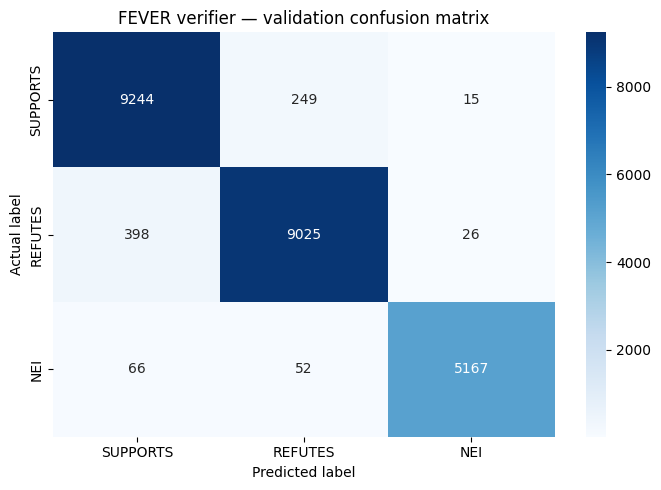

In [11]:
val_output = trainer.predict(dev_tokenized)
val_logits = val_output.predictions
val_true = val_output.label_ids
val_pred = np.argmax(val_logits, axis=1)

print("VALIDATION METRICS")
print("Accuracy:", accuracy_score(val_true, val_pred))
print("Macro-F1:", f1_score(val_true, val_pred, average="macro", zero_division=0))
print("Weighted-F1:", f1_score(val_true, val_pred, average="weighted", zero_division=0))
print("\\nClassification report:")
print(classification_report(
    val_true, val_pred,
    labels=[0,1,2],
    target_names=[ID2LABEL[i] for i in range(3)],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(val_true, val_pred, labels=[0,1,2])
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[ID2LABEL[i] for i in range(3)],
    yticklabels=[ID2LABEL[i] for i in range(3)]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("FEVER verifier — validation confusion matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_confusion_matrix.png", dpi=160)
plt.show()

## 11. Save per-example predictions and inspect errors

In [12]:
probs = torch.softmax(torch.tensor(val_logits), dim=1).numpy()
pred_df = pd.DataFrame({
    "id": [x["id"] for x in dev_rows],
    "claim": [x["claim"] for x in dev_rows],
    "evidence": [x["evidence_text"] for x in dev_rows],
    "evidence_source": [x["evidence_source"] for x in dev_rows],
    "gold_label": [ID2LABEL[int(x)] for x in val_true],
    "predicted_label": [ID2LABEL[int(x)] for x in val_pred],
    "confidence": probs.max(axis=1),
    "p_supports": probs[:, 0],
    "p_refutes": probs[:, 1],
    "p_nei": probs[:, 2],
})
pred_df["correct"] = pred_df["gold_label"] == pred_df["predicted_label"]

pred_path = OUTPUT_DIR / "validation_predictions.csv"
pred_df.to_csv(pred_path, index=False)
print("Saved:", pred_path)
print("Correct:", int(pred_df.correct.sum()), "/", len(pred_df))
print("Error count:", int((~pred_df.correct).sum()))

print("\\nMisclassified examples (first 20):")
display(pred_df.loc[~pred_df.correct, [
    "id", "gold_label", "predicted_label", "confidence",
    "claim", "evidence", "evidence_source"
]].head(20))

print("\\nErrors by gold label:")
display(
    pred_df.loc[~pred_df.correct].groupby("gold_label").size()
    .reindex(["SUPPORTS", "REFUTES", "NEI"], fill_value=0)
    .rename("error_count").to_frame()
)

Saved: /kaggle/working/fever_deberta_lora_final/validation_predictions.csv
Correct: 23436 / 24242
Error count: 806
\nMisclassified examples (first 20):


,id,gold_label,predicted_label,confidence,claim,evidence,evidence_source
40,195129,REFUTES,SUPPORTS,0.575319,Backing vocalists provide instrumental harmony.,Backing vocalists are singers who provide voca...,gold
73,66415,REFUTES,SUPPORTS,0.921761,Wilhelmina Slater's business partner is Vivian.,Wilhelmina Vivian Slater -LRB- born Wanda Slat...,gold
105,180722,REFUTES,NEI,0.957024,Victoria (Dance Exponents song) peaked at numb...,Released in 1982 it reached Number 6 on the Ne...,gold
146,16951,REFUTES,SUPPORTS,0.992588,The Premier League Asia Trophy is a battle.,The tournament format will be partly modified ...,gold
147,187571,REFUTES,SUPPORTS,0.999600,Dan Brown published a 2003 bestselling novel.,Daniel Gerhard `` Dan '' Brown -LRB- born June...,gold
152,30233,SUPPORTS,REFUTES,0.965206,The Love Club EP is too short to qualify as an...,The Love Club EP is the debut extended play -L...,gold
171,101619,SUPPORTS,REFUTES,0.656215,Ronaldinho has scored 33 goals for the Brazil ...,Ronaldinho has played 97 matches and scored 33...,gold
174,204356,REFUTES,SUPPORTS,0.996099,The Cretaceous is an event.,It is the last period of the Mesozoic Era .,gold
242,188994,REFUTES,SUPPORTS,0.899046,"William Cohen is from Bangor, Maine.","William Sebastian Cohen -LRB- born August 28 ,...",gold
243,93697,NEI,SUPPORTS,0.976373,Victoria Palace Theatre is in the West End and...,It is located at 1232 22nd Street NW in the We...,sampled_corpus


\nErrors by gold label:


,error_count
gold_label,
SUPPORTS,264
REFUTES,424
NEI,118


## 12. Label/evidence audit

Use this audit to revisit the earlier concern that the actual label may not agree with the evidence. A model prediction differing from the gold label is not by itself proof that the annotation is wrong. Check whether the evidence actually supports/refutes the claim, whether it is complete, and whether a sampled NEI sentence accidentally contains relevant information.

In [13]:
# Print a small, reproducible sample of errors for manual annotation review.
errors = pred_df.loc[~pred_df.correct].copy()
for _, row in errors.sample(min(10, len(errors)), random_state=SEED).iterrows():
    print("\\n" + "="*100)
    print("ID:", row["id"])
    print("GOLD:", row["gold_label"], "| PRED:", row["predicted_label"],
          "| CONF:", round(float(row["confidence"]), 4))
    print("EVIDENCE SOURCE:", row["evidence_source"])
    print("CLAIM:", row["claim"])
    print("EVIDENCE:", row["evidence"])

# Also inspect random NEI training examples for possible accidental relevant evidence.
nei_train = [r for r in train_rows if r["label_name"] == "NEI"]
print("\\nRandom NEI examples — manually verify these are genuinely insufficient:")
for row in random.Random(SEED).sample(nei_train, min(8, len(nei_train))):
    print("\\nClaim:", row["claim"])
    print("Evidence:", row["evidence_text"])

\n====================================================================================================
ID: 29256
GOLD: REFUTES | PRED: SUPPORTS | CONF: 0.9985
EVIDENCE SOURCE: gold
CLAIM: Agent Raghav – Crime Branch is a serial.
EVIDENCE: Agent Raghav -- Crime Branch is an Indian crime fiction anthology television series , which premiered on & TV from 5 September 2015 to 10 April 2016 for one hour at Saturday and Sunday nights .
\n====================================================================================================
ID: 22724
GOLD: REFUTES | PRED: SUPPORTS | CONF: 0.8881
EVIDENCE SOURCE: gold
CLAIM: The Hunger Games' second film is Mockingjay.
EVIDENCE: The Hunger Games : Mockingjay -- Part 1 -LRB- 2014 -RRB- had the largest opening day and weekend of 2014 . The Hunger Games -LRB- 2012 -RRB- set records for the opening day and the biggest opening weekend for a non-sequel film . The Hunger Games : Catching Fire -LRB- 2013 -RRB- set the record for biggest opening weekend in

## 13. Training curves and run summary

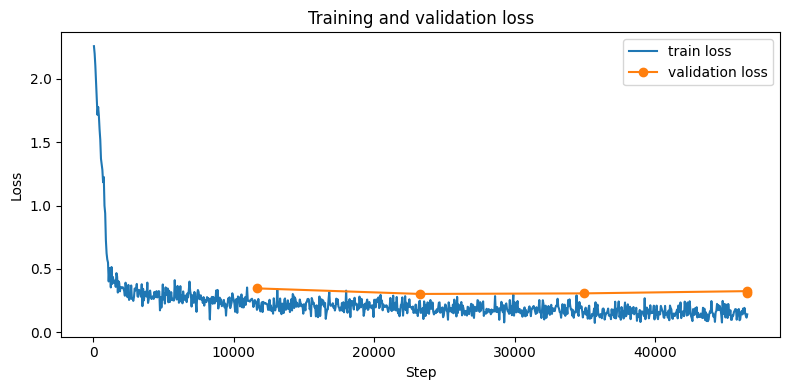

{'base_model': 'microsoft/deberta-v3-base',
 'method': 'LoRA sequence classification',
 'train_size': 186217,
 'validation_size': 24242,
 'train_label_distribution': {'SUPPORTS': 115573,
  'REFUTES': 42913,
  'NEI': 27731},
 'validation_label_distribution': {'NEI': 5285,
  'SUPPORTS': 9508,
  'REFUTES': 9449},
 'max_length': 256,
 'num_epochs': 4,
 'train_batch_size': 8,
 'eval_batch_size': 16,
 'gradient_accumulation_steps': 1,
 'warmup_steps': 1000,
 'transformers_version': '5.22.2',
 'peft_version': '0.21.2',
 'lora_r': 16,
 'lora_alpha': 32,
 'lora_dropout': 0.1,
 'lora_target_modules': ['query_proj', 'value_proj'],
 'training_seconds': 16963.476542949677,
 'validation_accuracy': 0.9667519181585678,
 'validation_macro_f1': 0.9694489217901804,
 'validation_weighted_f1': 0.966786168100575,
 'best_checkpoint': '/kaggle/working/fever_deberta_lora_final/checkpoints/checkpoint-34917'}

In [14]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUTPUT_DIR / "training_log_history.csv", index=False)

if "loss" in history:
    train_loss = history.dropna(subset=["loss"])
    plt.figure(figsize=(8,4))
    plt.plot(train_loss["step"], train_loss["loss"], label="train loss")
    if "eval_loss" in history:
        eval_loss = history.dropna(subset=["eval_loss"])
        if len(eval_loss):
            plt.plot(eval_loss["step"], eval_loss["eval_loss"], marker="o", label="validation loss")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=160)
    plt.show()

summary = {
    "base_model": MODEL_NAME,
    "method": "LoRA sequence classification",
    "train_size": len(train_rows),
    "validation_size": len(dev_rows),
    "train_label_distribution": dict(Counter(x["label_name"] for x in train_rows)),
    "validation_label_distribution": dict(Counter(x["label_name"] for x in dev_rows)),
    "max_length": MAX_LENGTH,
    "num_epochs": NUM_EPOCHS,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "warmup_steps": WARMUP_STEPS,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,
    "lora_target_modules": LORA_TARGET_MODULES,
    "training_seconds": training_seconds,
    "validation_accuracy": float(accuracy_score(val_true, val_pred)),
    "validation_macro_f1": float(f1_score(val_true, val_pred, average="macro", zero_division=0)),
    "validation_weighted_f1": float(f1_score(val_true, val_pred, average="weighted", zero_division=0)),
    "best_checkpoint": trainer.state.best_model_checkpoint,
}
with open(OUTPUT_DIR / "run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
summary

## 14. Optional: evaluate a separate untouched paper-dev or paper-test set

Only run this after choosing the model using the validation subset. This cell uses the prepared JSONL file as-is and does not train on it. Change `FINAL_EVAL_FILE` to `paper_dev_classifier.jsonl` or `paper_test_classifier.jsonl`. Do not use paper-test results to tune hyperparameters.

In [15]:
# OPTIONAL: run only when you are ready to report final test performance.
# Keep this False during training/model development to avoid repeatedly
# consulting the held-out paper test set.
RUN_FINAL_TEST = False
FINAL_EVAL_FILE = DATA_DIR / "paper_test_classifier.jsonl"

if RUN_FINAL_TEST:
    if not FINAL_EVAL_FILE.exists():
        raise FileNotFoundError(FINAL_EVAL_FILE)

    final_raw = read_jsonl(FINAL_EVAL_FILE)
    for row in final_raw:
        validate_row(row)

    final_rows = [to_model_row(r) for r in final_raw]
    final_ds = Dataset.from_list(final_rows).map(
        tokenize_batch, batched=True
    )
    final_ds = final_ds.remove_columns(
        [c for c in final_ds.column_names if c not in keep_columns]
    )

    final_result = trainer.predict(final_ds)
    final_true = final_result.label_ids
    final_pred = np.argmax(final_result.predictions, axis=1)

    print("FINAL HELD-OUT TEST REPORT")
    print(classification_report(
        final_true, final_pred,
        labels=[0, 1, 2],
        target_names=[ID2LABEL[i] for i in range(3)],
        digits=4,
        zero_division=0
    ))
    print("Accuracy:", accuracy_score(final_true, final_pred))
    print("Macro-F1:", f1_score(
        final_true, final_pred, average="macro", zero_division=0
    ))

    test_predictions = pd.DataFrame({
        "id": [x["id"] for x in final_rows],
        "claim": [x["claim"] for x in final_rows],
        "evidence": [x["evidence_text"] for x in final_rows],
        "gold_label": [ID2LABEL[int(x)] for x in final_true],
        "predicted_label": [ID2LABEL[int(x)] for x in final_pred],
    })
    test_predictions.to_csv(
        OUTPUT_DIR / "final_test_predictions.csv", index=False
    )
else:
    print("Held-out test evaluation skipped (RUN_FINAL_TEST=False).")


Held-out test evaluation skipped (RUN_FINAL_TEST=False).


## Notes / limitations

1. **This is LoRA, not QLoRA.** The frozen base model is loaded in its normal precision. LoRA reduces trainable parameters and optimizer state; it does not quantize the backbone.
2. CPU inference is still possible by loading the base model plus adapter on CPU, but CPU speed depends on model size, sequence length, batch size, and hardware. For faster deployment, merge the adapter and evaluate INT8 dynamic quantization or ONNX Runtime separately.
3. The prepared dataset's NEI evidence is randomly sampled. A sampled sentence can accidentally be relevant, creating label noise. Manual audit or hard-negative filtering can improve this.
4. The notebook treats each alternative gold evidence group as a separate positive training example. Claims with multiple gold groups therefore appear multiple times, which is intentional for group-level supervision.
5. Subset metrics are for rapid iteration, not final paper results. Once the pipeline is stable, train with the full official training split and evaluate once on the untouched test split.